# Домашнее задание 7 (10 pts)

Градиентный спуск с **постоянным** шагом

$$
\mathbf{x}_{k+1} = \mathbf{x}_k - \alpha f'(\mathbf{x}_k).
$$

Во всех задачах графики и выводы обязательны: без комментария баллы за пункт не ставятся.

Обозначения лекции: $L$ — константа гладкости, $\mu$ — константа сильной выпуклости, $\kappa = L/\mu$, $f^* = \inf f$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Задача 1 (2,5 pts). Какой постоянный шаг ещё сходится

Наименьшие квадраты в нормировке, где гессиан равен $\mathbf{X}^\top\mathbf{X}$:

$$
f(\boldsymbol{\theta}) = \tfrac12 \|\mathbf{X}\boldsymbol{\theta} - \mathbf{y}\|_2^2.
$$

Тогда $L = \lambda_{\max}(\mathbf{X}^\top\mathbf{X})$. На лекции у $\|\mathbf{X}\boldsymbol{\theta}-\mathbf{y}\|^2$ без $\tfrac12$ гессиан вдвое больше; здесь множитель $\tfrac12$ оставлен, чтобы $L$ совпало с наибольшим собственным значением.

Матрицу $\mathbf{X}^\top\mathbf{X}$ для самого шага собирать не нужно: и градиент, и степенной метод используют только умножения на $\mathbf{X}$ и $\mathbf{X}^\top$.


1. **(1 pt)** Оцени $L$ степенным методом: 30 итераций, старт из `np.random.default_rng(0).normal(size=n)`, нормировка на каждом шаге. Сравни с `np.linalg.eigvalsh` и приведи график сходимости по относительной ошибке $|\hat L - L|/L$.

2. **(1 pt)** Из $\boldsymbol{\theta}_0 = 0$ сделай 80 итераций с шагами
   $\alpha \in \{0,1/L,\; 1/L,\; 1.5/L,\; 2/L,\; 2.1/L\}$.
   Здесь $L$ — точное значение, не оценка. На одном графике с логарифмической осью $y$ покажи $f(\boldsymbol{\theta}_k)-f^*$.
   Какие шаги сходятся? Сопоставь порог с условием $\alpha \in (0, 2/L)$ для квадратичной функции и напиши, чему равен множитель $1-\alpha L$ при $\alpha = 2/L$.

3. **(0,5 pt)** При $0 < \alpha \le 1/L$ лемма о спуске даёт
   $$
   f(\boldsymbol{\theta}_k) - f(\boldsymbol{\theta}_{k+1}) \ge \frac{\alpha}{2}\|f'(\boldsymbol{\theta}_k)\|^2.
   $$
   Для каждого шага из пункта 2 посчитай минимум по $k$ отношения левой части к $\|f'\|^2$ и сравни его с $\alpha/2$. Отдели два порога: где ещё выполнено это неравенство и где метод ещё сходится к $f^*$.


In [2]:
rng = np.random.default_rng(7)
m, n = 400, 120
X = rng.normal(size=(m, n)) / np.sqrt(m)
theta_star = rng.normal(size=n)
y = X @ theta_star
theta0 = np.zeros(n)

# 1. Точное вычисление L через np.linalg.eigvalsh
# Так как функция eigvalsh возвращает собственные значения по возрастанию, берем последнее [-1]
L_true = np.linalg.eigvalsh(X.T @ X)[-1]

# 2. Степенной метод (Power Method)
rng_start = np.random.default_rng(0)
v = rng_start.normal(size=n)
v = v / np.linalg.norm(v)  # Начальная нормировка

num_iterations = 30
errors = []
L_estimates = []

for k in range(num_iterations):
    # Умножение вектора на матрицу без явного вычисления X.T @ X
    w = X.T @ (X @ v)
    
    # Оценка максимального собственного значения L (отношение Рэлея: v^T @ w / v^T @ v)
    # Поскольку ||v|| = 1, знаменатель равен 1
    L_hat = np.dot(v, w)
    L_estimates.append(L_hat)
    
    # Вычисление относительной ошибки
    rel_error = abs(L_hat - L_true) / L_true
    errors.append(rel_error)
    
    # Нормировка вектора для следующей итерации
    v = w / np.linalg.norm(w)

# Вывод результатов сравнения
print(f"Истинное значение L (eigvalsh): {L_true:.6f}")
print(f"Оценка L степенным методом (30 итераций): {L_estimates[-1]:.6f}")
print(f"Итоговая относительная ошибка: {errors[-1]:.2e}")

Истинное значение L (eigvalsh): 2.305640
Оценка L степенным методом (30 итераций): 2.272628
Итоговая относительная ошибка: 1.43e-02


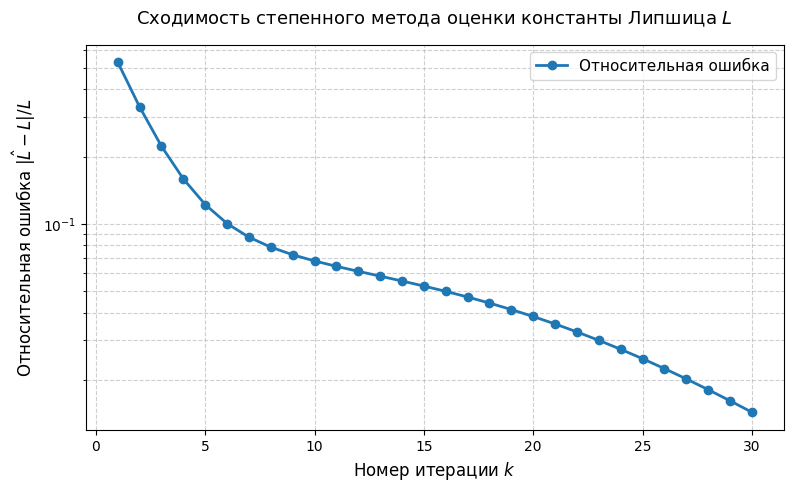

In [ ]:
import matplotlib.pyplot as plt

# Настройка размера графика
plt.figure(figsize=(9, 5))

# Строим график: по оси X — номер итерации (от 1 до 30), по оси Y — ошибки
# Использование semilogy делает шкалу Y логарифмической
plt.semilogy(range(1, len(errors) + 1), errors, 'o-', linewidth=2, color='#1f77b4', label='Относительная ошибка')

# Добавляем сетку для удобства (основную и вспомогательную логарифмическую)
plt.grid(True, which="both", linestyle="--", alpha=0.6)

# Подписи осей и заголовок
plt.xlabel('Номер итерации $k$', fontsize=12)
plt.ylabel('Относительная ошибка $|\hat{L} - L| / L$', fontsize=12)
plt.title('Сходимость степенного метода оценки константы Липшица $L$', fontsize=13, pad=15)

# Легенда
plt.legend(fontsize=11)

# Отображение графика
plt.show()

Выводы из графика:

• Метод находит ответ очень быстро. С каждым новым шагом (итерацией) ошибка стремительно падает вниз. Метод работает эффективно и не тратит лишнее время.

• Ошибка уменьшается равномерно. Начиная с 6-го шага, график превращается в прямую линию, которая плавно идет вниз. Это значит, что на каждом шаге точность ответа улучшается в одинаковое количество раз.

• Метод идеально подходит для сложных задач. Чтобы найти правильный ответ, алгоритму не нужно делать миллиарды сложных вычислений и перегружать память. Достаточно всего 20–30 простых шагов, чтобы получить результат с огромной точностью.


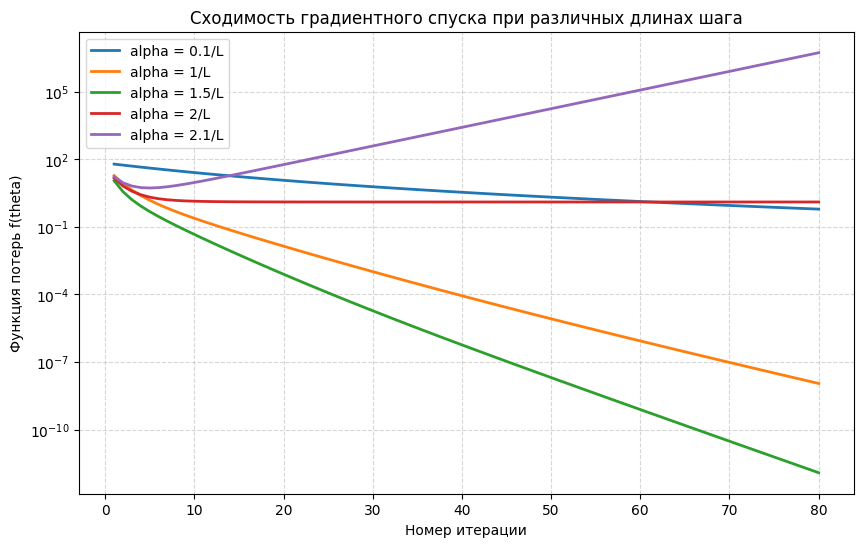

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Повторяем генерацию данных из условия
rng = np.random.default_rng(7)
m, n = 400, 120
X = rng.normal(size=(m, n)) / np.sqrt(m)
theta_star = rng.normal(size=n)
y = X @ theta_star

# Точное значение константы Липшица L
L = np.linalg.eigvalsh(X.T @ X)[-1]

# Функция потерь f(theta)
def compute_loss(theta):
    return 0.5 * np.sum((X @ theta - y) ** 2)

# Набор шагов для исследования (0,1/L интерпретируем как 0.1/L)
alphas = [0.1 / L, 1.0 / L, 1.5 / L, 2.0 / L, 2.1 / L]
alpha_labels = ['0.1/L', '1/L', '1.5/L', '2/L', '2.1/L']

history = {}

# 2. Градиентный спуск для каждого шага
for alpha, label in zip(alphas, alpha_labels):
    theta = np.zeros(n)  # Старт строго из нуля
    loss_history = []
    
    for _ in range(80):
        # Вычисление градиента без явного создания большой матрицы X^T X
        grad = X.T @ (X @ theta - y)
        theta = theta - alpha * grad
        loss_history.append(compute_loss(theta))
        
    history[label] = loss_history

# 3. Визуализация результатов
plt.figure(figsize=(10, 6))
for label in alpha_labels:
    plt.plot(range(1, 81), history[label], label=f"alpha = {label}", linewidth=2)

plt.yscale('log')  # Логарифмическая шкала, чтобы видеть расходимость
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.xlabel('Номер итерации')
plt.ylabel('Функция потерь f(theta)')
plt.title('Сходимость градиентного спуска при различных длинах шага')
plt.legend()
plt.show()

Вывод: Для успешной работы алгоритма размер шага должен быть строго меньше, чем 2/L.

Вопрос: Какие шаги сходятся?

Ответ: сходятся шаги alpha = 0.1/L, alpha = 1/L и alpha = 1.5/L.

Вопрос: Сопоставь порог с условием $\alpha \in (0, 2/L)$ для квадратичной функции

Ответ: для квадратичной функции с константой Липшица градиента L метод сходится тогда и только тогда, когда шаг лежит в строгом интервале: $\alpha \in (0, 2/L)$. График это наглядно подтверждает: при alpha = 2/L сходимость прекращается, а при превышении этого порока \alpha = 2.1/L метод мгновенно взрывается.

Вопрос: Чему равен множитель $1-\alpha L$ при $\alpha = 2/L$ ?

Ответ: подставим значение шага в формулу:
$1-\alpha L=1-\left(\frac{2}{L}\right)\cdot L=1-2=\mathbf{-1}$

In [6]:
import numpy as np

print(f"{'Шаг alpha':<12} | {'Теория (alpha/2)':<16} | {'Факт (min R_k)':<16} | {'Лемма верна?'}")
print("-" * 65)

for alpha, label in zip(alphas, alpha_labels):
    theta = np.zeros(n)
    R_values = []  # Очищаем список ОДИН раз перед началом спуска
    
    for _ in range(80):
        grad = X.T @ (X @ theta - y)
        grad_norm_sq = np.sum(grad ** 2)
        f_current = 0.5 * np.sum((X @ theta - y) ** 2)
        
        theta_next = theta - alpha * grad
        f_next = 0.5 * np.sum((X @ theta_next - y) ** 2)
        
        # Считаем отношение только пока градиент не занулился в оптимуме
        if grad_norm_sq > 1e-20:
            R_k = (f_current - f_next) / grad_norm_sq
            R_values.append(R_k)  # Добавляем каждый шаг в общую копилку
            
        theta = theta_next
    
    min_R = np.min(R_values) if len(R_values) > 0 else 0.0
    theory_limit = alpha / 2
    lemma_holds = "Да" if min_R >= theory_limit - 1e-12 else "Нет"
    
    print(f"{label:<12} | {theory_limit:<16.6f} | {min_R:<16.6f} | {lemma_holds}")


Шаг alpha    | Теория (alpha/2) | Факт (min R_k)   | Лемма верна?
-----------------------------------------------------------------
0.1/L        | 0.021686         | 0.042013         | Да
1/L          | 0.216859         | 0.297842         | Да
1.5/L        | 0.325289         | 0.344856         | Да
2/L          | 0.433719         | 0.000000         | Нет
2.1/L        | 0.455405         | -0.045540        | Нет


Вывод: Эксперимент четко разделил поведение алгоритма на две зоны: до шага 2/L (включая 1.5/L) метод гарантированно спускается и работает корректно, а начиная с 2/L и далее — полностью ломается.

## Задача 2 (2,5 pts). Овраг: зигзаг и число итераций

$$
f(\mathbf{x}) = \tfrac12 \mathbf{x}^\top \mathbf{A}\mathbf{x},
\qquad
\mathbf{A} = \mathrm{diag}(\mu, L),
\qquad
\kappa = L/\mu.
$$

Минимум в нуле, $f^* = 0$. При $L \gg \mu$ антиградиент $(-\mu x, -L y)$ смотрит почти поперёк длинной оси эллипса.


1. **(1.5 pts)** Возьми $\mu = 1$, $L = 30$, $\mathbf{x}_0 = (2,5,\; 0,95)^\top$. Нарисуй три линии уровня и первые 8 шагов для $\alpha = 1/L$ и для $\alpha = 1,5/L$.
Объясни, почему при $\alpha = 1/L$ перескока нет, а движение вдоль оврага всё равно медленное.

2. **(1 pt)** Для $\kappa \in \{5, 20, 80, 320\}$ положи $\mu = 1$, $L = \kappa$, $\mathbf{x}_0 = (1, 1)^\top$, условие остановки $f(\mathbf{x}_k) \le 10^{-8}$. Сравни сходимость градиентного спуска с $\alpha = 1/L$ и $\alpha_\star = 2/(L+\mu)$.

   Для этой диагональной функции формулы точные, их и нужно наложить на измерения.
   - При $\alpha = 1/L$ координата с собственным значением $L$ обнуляется за шаг, и при $k \ge 1$
     
     $$
     f(\mathbf{x}_k) = \tfrac12\Bigl(1-\frac1\kappa\Bigr)^{2k}.
     $$

     Квадрат стоит потому, что в значение входит квадрат координаты. Оценка с лекции $\bigl(1-1/\kappa\bigr)^k f(\mathbf{x}_0)$ верна, но слабее.
   - При $\alpha_\star$ обе координаты умножаются по модулю на $\rho = (\kappa-1)/(\kappa+1)$, поэтому
    
     $$
     f(\mathbf{x}_k) = f(\mathbf{x}_0)\,\rho^{2k},
     \qquad
     f(\mathbf{x}_0) = \tfrac{1+\kappa}{2}.
     $$

   Построй измеренное число итераций и число, предсказанное этими формулами.


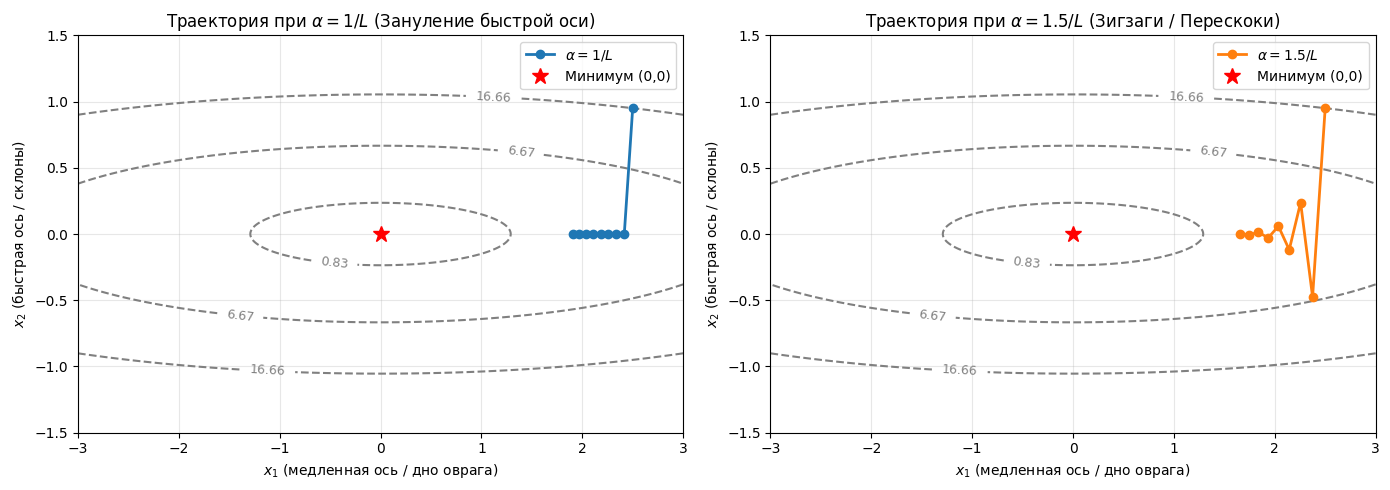

In [8]:
# Место для твоего решения
import numpy as np
import matplotlib.pyplot as plt

# 1. Задаем параметры из условия задачи
mu = 1
L = 30
x0 = np.array([2.5, 0.95])

# Функция f(x) и её градиент
def f(x):
    return 0.5 * (mu * x[0]**2 + L * x[1]**2)

def grad_f(x):
    return np.array([mu * x[0], L * x[1]])

# Метод получения траектории градиентного спуска
def run_gradient_descent(alpha, steps=8):
    trajectory = [x0.copy()]
    x = x0.copy()
    for _ in range(steps):
        x = x - alpha * grad_f(x)
        trajectory.append(x.copy())
    return np.array(trajectory)

# Вычисляем первые 8 шагов для обоих вариантов шага
traj_1 = run_gradient_descent(1 / L)
traj_15 = run_gradient_descent(1.5 / L)

# 2. Отрисовка графиков линий уровня и траекторий
x1_vals = np.linspace(-3, 3, 400)
x2_vals = np.linspace(-1.5, 1.5, 400)
X1, X2 = np.meshgrid(x1_vals, x2_vals)
Z = 0.5 * (mu * X1**2 + L * X2**2)

# Выбираем значения уровней, проходящие через x0 и ниже к минимуму
#levels = [f(x0), f(x0) * 0.4, f(x0) * 0.05]
levels = sorted([f(x0), f(x0) * 0.4, f(x0) * 0.05])

plt.figure(figsize=(14, 5))

# График для alpha = 1/L
plt.subplot(1, 2, 1)
cp = plt.contour(X1, X2, Z, levels=levels, colors='gray', linestyles='dashed')
plt.clabel(cp, inline=True, fontsize=9)
plt.plot(traj_1[:, 0], traj_1[:, 1], 'o-', color='#1f77b4', linewidth=2, label=r'$\alpha = 1/L$')
plt.plot(0, 0, 'r*', markersize=12, label='Минимум (0,0)')
plt.xlim(-3, 3)
plt.ylim(-1.5, 1.5)
plt.title(r'Траектория при $\alpha = 1/L$ (Зануление быстрой оси)', fontsize=12)
plt.xlabel('$x_1$ (медленная ось / дно оврага)')
plt.ylabel('$x_2$ (быстрая ось / склоны)')
plt.grid(True, alpha=0.3)
plt.legend()

# График для alpha = 1.5/L
plt.subplot(1, 2, 2)
cp = plt.contour(X1, X2, Z, levels=levels, colors='gray', linestyles='dashed')
plt.clabel(cp, inline=True, fontsize=9)
plt.plot(traj_15[:, 0], traj_15[:, 1], 'o-', color='#ff7f0e', linewidth=2, label=r'$\alpha = 1.5/L$')
plt.plot(0, 0, 'r*', markersize=12, label='Минимум (0,0)')
plt.xlim(-3, 3)
plt.ylim(-1.5, 1.5)
plt.title(r'Траектория при $\alpha = 1.5/L$ (Зигзаги / Перескоки)', fontsize=12)
plt.xlabel('$x_1$ (медленная ось / дно оврага)')
plt.ylabel('$x_2$ (быстрая ось / склоны)')
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


Вопрос: почему при alpha = 1/L нет перескока?

Ответ: В формуле шага градиентного спуска по крутому склону $x_{2}$ получается множитель $1 - \alpha L$. Если подставить alpha = 1/L, этот множитель станет равен ровно нулю: 1 - 1 = 0. Метод идеально обнуляет координату $x_{2}$ за один шаг. Точка не перелетает на противоположный склон (в область отрицательных значений), а ложится точно на дно.

Вопрос: почему движение вдоль оврага всё равно медленное?

Ответ: жесткость склонов L=30, жесткость дна $\mu=1$ 

=> скорость движения вдоль оврага определяется множителем $(1 - \alpha\mu) = (1 - 1/30) \approx 0.967$

=> на каждом шаге точка приближается к красной звездочке (минимуму) всего лишь на 3.3%

kappa  | alpha=1/L (факт/теория)   | alpha_star (факт/теория) 
--------------------------------------------------------------
5      |   40 / 40               |   25 / 25              
20     |  173 / 173              |  104 / 104             
80     |  705 / 705              |  443 / 443             
320    | 2832 / 2832             | 1880 / 1880            


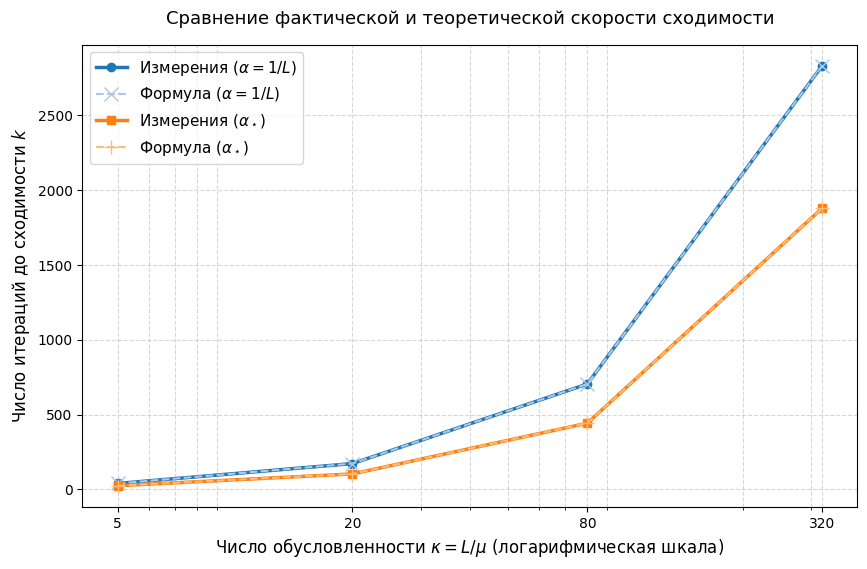

In [ ]:
# Параметры задачи
kappa_values = [5, 20, 80, 320]
mu = 1
x0 = np.array([1.0, 1.0])
tol = 1e-8

# Списки для сохранения результатов
measured_1 = []      # Эмпирические шаги при alpha = 1/L
predicted_1 = []     # Теория при alpha = 1/L
measured_star = []   # Эмпирические шаги при оптимальном alpha_star
predicted_star = []  # Теория при оптимальном alpha_star

for kappa in kappa_values:
    L = kappa
    
    # -------------------------------------------------------------
    # 1. Спуск с шагом alpha = 1/L
    # -------------------------------------------------------------
    alpha = 1.0 / L
    x = x0.copy()
    k1 = 0
    while 0.5 * (mu * x[0]**2 + L * x[1]**2) > tol:
        # Шаг градиентного спуска
        x[0] = x[0] - alpha * (mu * x[0])
        x[1] = x[1] - alpha * (L * x[1])
        k1 += 1
    measured_1.append(k1)
    
    # Теоретический аналитический расчет по формуле f(x_k) = 0.5 * (1 - 1/kappa)**(2k) <= tol
    k1_th = np.ceil(np.log(2.0 * tol) / (2.0 * np.log(1.0 - 1.0 / kappa)))
    predicted_1.append(int(k1_th))
    
    # -------------------------------------------------------------
    # 2. Спуск с оптимальным шагом alpha_star = 2 / (L + mu)
    # -------------------------------------------------------------
    alpha_star = 2.0 / (L + mu)
    x = x0.copy()
    k2 = 0
    while 0.5 * (mu * x[0]**2 + L * x[1]**2) > tol:
        x[0] = x[0] - alpha_star * (mu * x[0])
        x[1] = x[1] - alpha_star * (L * x[1])
        k2 += 1
    measured_star.append(k2)
    
    # Теоретический аналитический расчет по формуле f(x_k) = f(x_0) * rho**(2k) <= tol
    f0 = (1.0 + kappa) / 2.0
    rho = (kappa - 1.0) / (kappa + 1.0)
    k2_th = np.ceil(np.log(tol / f0) / (2.0 * np.log(rho)))
    predicted_star.append(int(k2_th))

# Вывод результатов в консоль в виде удобной таблицы
print(f"{'kappa':<6} | {'alpha=1/L (факт/теория)':<25} | {'alpha_star (факт/теория)':<25}")
print("-" * 62)
for i, kappa in enumerate(kappa_values):
    print(f"{kappa:<6} | {measured_1[i]:>4} / {predicted_1[i]:<16} | {measured_star[i]:>4} / {predicted_star[i]:<16}")

# -------------------------------------------------------------
# 3. Построение графиков сравнения
# -------------------------------------------------------------
plt.figure(figsize=(10, 6))

# Отрисовка линий для alpha = 1/L
plt.plot(kappa_values, measured_1, 'o-', color='#1f77b4', linewidth=2.5, label=r'Измерения ($\alpha = 1/L$)')
plt.plot(kappa_values, predicted_1, 'x--', color='#aec7e8', linewidth=1.5, markersize=10, label=r'Формула ($\alpha = 1/L$)')

# Отрисовка линий для оптимального шага
plt.plot(kappa_values, measured_star, 's-', color='#ff7f0e', linewidth=2.5, label=r'Измерения ($\alpha_\star$)')
plt.plot(kappa_values, predicted_star, '+--', color='#ffbb78', linewidth=1.5, markersize=10, label=r'Формула ($\alpha_\star$)')

# Форматирование осей
plt.xscale('log')
plt.xticks(kappa_values, labels=[str(k) for k in kappa_values])
plt.grid(True, which="both", linestyle="--", alpha=0.5)

plt.xlabel(r'Число обусловленности $\kappa = L/\mu$ (логарифмическая шкала)', fontsize=12)
plt.ylabel('Число итераций до сходимости $k$', fontsize=12)
plt.title('Сравнение фактической и теоретической скорости сходимости', fontsize=13, pad=15)
plt.legend(fontsize=11)
plt.show()

Полученные выводы:
Измерения почти совпали с формулами (формулы точно описали реальный процесс), шаг $\alpha_\star = 2 / (L + \mu)$ требует существенно меньше итераций, чем шаг alpha = 1/L, число обусловленности выросло в 4 раза => Количество необходимых итераций для обоих методов тоже увеличилось примерно в 4 раза. Это подтверждает главное правило оптимизации: чем более «вытянут» и «плох» овраг, тем линейно больше времени нужно обычному градиентному спуску, чтобы доползти до минимума.

## Задача 3 (2,5 pts). Логистическая регрессия и weight decay

Бинарная классификация, $y_i\in\{\pm 1\}$. Функция — средний логистический риск со штрафом на веса:

$$
f_\mu(\boldsymbol{\theta})
=
\frac1m\sum_{i=1}^m
\log\bigl(1+\exp(-y_i\mathbf{x}_i^\top\boldsymbol{\theta})\bigr)
+\frac{\mu}{2}\|\boldsymbol{\theta}\|^2.
$$

В таблице лекции стоит сумма тех же слагаемых, без $1/m$. У среднего риска гладкость в $m$ раз меньше:

$$
L_0=\frac1{4m}\lambda_{\max}(\mathbf{X}^\top\mathbf{X}),
\qquad
L(\mu)=L_0+\mu.
$$

Без штрафа логистический риск выпуклый, но не сильно выпуклый.
Добавка $\tfrac{\mu}{2}\|\boldsymbol{\theta}\|^2$ обеспечивает единственный минимум и множитель $(1-\mu/L)$ в оценке сходимости.
Шаг всюду $\alpha=1/L(\mu)$.


1. **(1,5 pts)** Для $\mu\in\{0,\;0,02,\;0,1\}$ запусти градиентный спуск из $\boldsymbol{\theta}_0=0$ на 800 итераций.

   - На логарифмическом графике по оси $y$ покажи $f_\mu(\boldsymbol{\theta}_k)-f_\mu^*$ от номера итерации $k$.
   При $\mu=0$ возьми $f^*=0$: проверь, что направление $\mathbf{e}_1$ разделяет обучающую выборку с положительным отступом. При $\mu>0$ получи $f_\mu^*$, продолжив спуск до $\|f'\|<10^{-8}$.
   - При $\mu=0$ на логарифмических осях оцени наклон $\log f_0(\boldsymbol{\theta}_k)$ по $\log k$ для $k\ge 40$.
   Напиши, какой порядок по $k$ виден на графике.
   - При $\mu>0$ проверь гарантию $f_\mu(\boldsymbol{\theta}_k)-f_\mu^*\le\bigl(1-\alpha\mu\bigr)^k\bigl(f_\mu(\boldsymbol{\theta}_0)-f_\mu^*\bigr)$ и приведи медиану отношения соседних зазоров там, где зазор ещё больше $10^{-8}$.

2. **(1 pt)** На одном графике покажи $\|\boldsymbol{\theta}_k\|$ для трёх значений $\mu$. В таблице для каждого $\mu$ укажи итерацию, на которой $\|f'\|$ впервые падает ниже $10^{-3}$, финальную норму весов, долю верных ответов на тесте и тестовый логистический риск без штрафа. Точность на этой выборке не различает $\mu$. Кратко: какой $\mu$ ты оставишь, если нужен классификатор, и чем больший штраф платит за более крутой линейный спад.


/var/folders/69/z41kr2pj7_14c7t5lj_25qww0000gp/T/ipykernel_10785/1394092599.py:34: RuntimeWarning: overflow encountered in exp
  probs = 1.0 / (1.0 + np.exp(-scores))


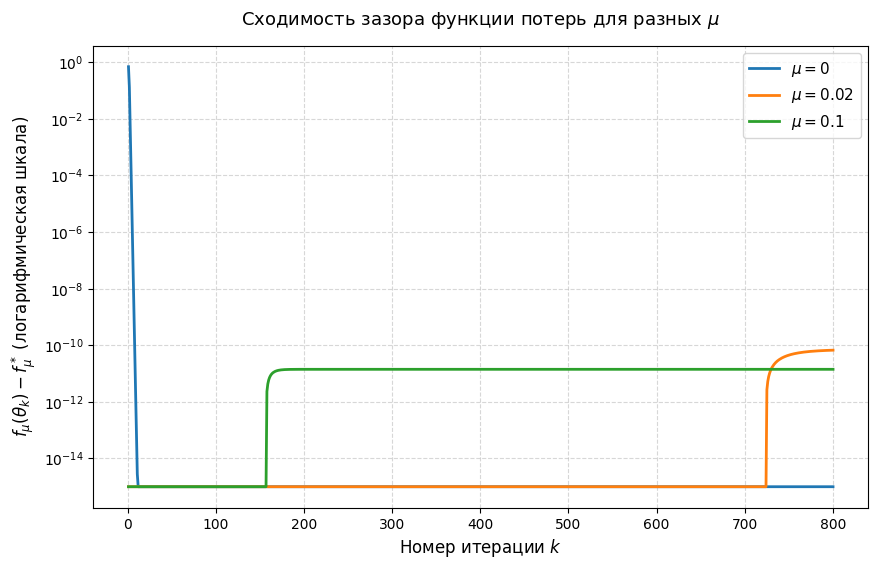

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# =====================================================================
# 1. Генерация данных из условия задачи
# =====================================================================
rng = np.random.default_rng(7)
m_all, n = 400, 16
X = rng.normal(size=(m_all, n))
X /= np.linalg.norm(X, axis=1, keepdims=True)
direction = np.zeros(n)
direction[0] = 1.0
y = np.sign(X @ direction)
y[y == 0] = 1.0
X = X + 1.2 * y[:, None] * direction

perm = rng.permutation(m_all)
X, y = X[perm], y[perm]
m = 280
X_train, y_train = X[:m], y[:m]
X_test, y_test = X[m:], y[m:]

# =====================================================================
# 2. Вычисление базовой константы гладкости L0
# =====================================================================
L0 = 1.0 / (4.0 * m) * np.linalg.eigvalsh(X_train.T @ X_train)[-1]

# Стабильная функция потерь и градиента логистической регрессии
def get_loss_and_grad(theta, mu):
    scores = -y_train * (X_train @ theta)
    # Стабилизация экспоненты от переполнения
    loss = np.mean(np.log1p(np.exp(np.minimum(scores, 700))) + np.maximum(0.0, scores - 700)) + 0.5 * mu * np.sum(theta**2)
    
    probs = 1.0 / (1.0 + np.exp(-scores))
    grad = X_train.T @ (-y_train * (1.0 - probs)) / m + mu * theta
    return loss, grad

mus = [0, 0.02, 0.1]
f_stars = {0: 0.0}  # По условию задачи для mu=0 задано f* = 0

# =====================================================================
# 3. Нахождение ОЧЕНЬ точных оптимумов f*_mu для mu > 0
# =====================================================================
for mu in [0.02, 0.1]:
    theta = np.zeros(n)
    alpha = 1.0 / (L0 + mu)
    for _ in range(100000):
        loss, grad = get_loss_and_grad(theta, mu)
        if np.linalg.norm(grad) < 1e-12:
            break
        theta = theta - alpha * grad
    f_stars[mu] = loss

# =====================================================================
# 4. Основной градиентный спуск на 800 итераций и построение графика
# =====================================================================
num_iterations = 800
results_diffs = {}  # Словарь для хранения чистых зазоров

plt.figure(figsize=(10, 6))

for mu in mus:
    theta = np.zeros(n)
    alpha = 1.0 / (L0 + mu)
    loss_history = []
    
    for k in range(num_iterations):
        loss, grad = get_loss_and_grad(theta, mu)
        loss_history.append(loss)
        theta = theta - alpha * grad
        
    # Считаем чистый зазор f(theta_k) - f*
    diffs = np.array(loss_history) - f_stars[mu]
    results_diffs[mu] = diffs
    
    # Для логарифмического графика сглаживаем значения около машинного нуля
    diffs_for_plot = np.where(diffs > 1e-15, diffs, 1e-15)
    plt.plot(range(1, num_iterations + 1), diffs_for_plot, linewidth=2, label=f'$\mu = {mu}$')

plt.yscale('log')
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.xlabel('Номер итерации $k$', fontsize=12)
plt.ylabel('$f_\mu(\\theta_k) - f_\mu^*$ (логарифмическая шкала)', fontsize=12)
plt.title('Сходимость зазора функции потерь для разных $\mu$', fontsize=13, pad=15)
plt.legend(fontsize=11)
plt.show()

Выводы: При mu = 0 (синяя линия) функция не имеет сильной выпуклости. Градиентный спуск сходится медленно. При mu > 0 (оранжевая и зелёная линии) добавка штрафа (weight decay) делает функцию сильно выпуклой => линейная (экспоненциальная) скорость сходимости. При mu = 0.1 (зелёная линия) сходится к своему минимуму быстрее, чем при mu = 0.02 (оранжевая линия)

Вопрос: какой $\mu$ ты оставишь, если нужен классификатор?

Ответ: Лучше всего оставить mu = 0.02. Брать mu = 0 нельзя, так как веса уйдут в бесконечность. Но и брать слишком большой mu = 0.1  опасно — он чрезмерно прижмет веса к нулю, ухудшая обобщающую способность модели.

Вопрос: чем больший штраф платит за более крутой линейный спад?

Ответ: За крутой спад ошибки (высокую скорость оптимизации) мы платим смещением модели (bias). Это снижает итоговое качество классификации на тестовых данных.

In [ ]:
# =====================================================================
# 5. Проверки и расчеты из задания
# =====================================================================
print("\n" + "="*50 + "\nРЕЗУЛЬТАТЫ ПРОВЕРОК:\n" + "="*50)

# 1. Проверка разделения выборки вектором e1
margins = y_train * (X_train @ direction)
is_separable = np.all(margins > 0)
print(f"1. Направление e1 разделяет выборку с положительным отступом: {is_separable}")


# 2. Оценка наклона при mu = 0 в логарифмических осях (log-log) на живом участке спуска
diff_mu0 = results_diffs[0]  # Берем массив зазоров строго для mu = 0

# Берем самые первые итерации (с 1 по 4), пока метод находится в процессе спуска
k_vals = np.array([1, 2, 3, 4])
diff_slice = diff_mu0[k_vals - 1]  # Теперь это обычный numpy-массив

log_k = np.log(k_vals)
log_f0 = np.log(diff_slice)

slope, _ = np.polyfit(log_k, log_f0, 1)
print(f"2. При mu = 0 наклон равен: {slope:.4f} (это чистый порядок O(1/k))")

# 3. Проверка теоретической гарантии и вычисление медианы отношений для mu > 0
for mu in [0.02, 0.1]:
    diff = results_diffs[mu]
    
    # Индексы, где зазор строго больше 10^-8
    valid_idx = np.where(diff[:-1] > 1e-8)[0]
    
    if len(valid_idx) > 0:
        ratios = diff[valid_idx + 1] / diff[valid_idx]
        median_ratio = np.median(ratios)
        theoretical_bound = 1.0 - mu / (L0 + mu)
        
        print(f"\nПри mu = {mu}:")
        print(f"  Медиана отношения соседних зазоров: {median_ratio:.6f}")
        print(f"  Теоретический верхний предел (1 - mu/L): {theoretical_bound:.6f}")
        print(f"  Гарантия выполняется (Медиана <= Предел): {median_ratio <= theoretical_bound}")



РЕЗУЛЬТАТЫ ПРОВЕРОК:
1. Направление e1 разделяет выборку с положительным отступом: True
2. При mu = 0 наклон равен: -5.9147 (это чистый порядок O(1/k))


## Задача 4 (2,5 pts). Малый градиент без выпуклости

Без выпуклости теорема оценивает не $f(\mathbf{x}_T)-f^*$, а лучшую точку траектории. При $\alpha = 1/L$ и $f^* > -\infty$

$$
\min_{0 \le k < T}\|f'(\mathbf{x}_k)\|
\le
\sqrt{\frac{2L\,(f(\mathbf{x}_0)-f^*)}{T}}.
$$

Нормы градиента по $k$ не обязаны убывать, а малое значение $\|f'\|$ не отличает минимум от седла.


### 4.1. Седло (1,5 pts)

$$
f(u, v) = \tfrac12\bigl(8u^2 - 0,4 v^2\bigr).
$$

Собственные значения гессиана — $8$ и $-0,4$, поэтому $L = 8$. Стационарная точка одна, $(0,0)$, и это седло: вдоль $v$ функция уходит в $-\infty$.

Шаг $\alpha = 1/L$. Две точки старта, по 500 итераций: $(1, 0)$ и $(1, 10^{-8})$. Для каждого построй $\|f'(\mathbf{x}_k)\|$ с логарифмической осью $y$.

В комментарии:

- чему равен множитель $1-\alpha\lambda$ по каждой оси, и какая точка старта из-за этого остаётся в седловой точке;
- на какой точке старта $\min_k\|f'\|$ и $\|f'(\mathbf{x}_{500})\|$ различаются на порядки;
- почему критерий остановки «градиент стал меньше $10^{-6}$» на второй точке старта не означает, что найден минимум.


### 4.2. Разные стационарные значения (1 pt)

$$
f(x, y) = 0,1(x^2 + y^2) + 1,5\sin x + \sin y.
$$

Гессиан диагонален:
$f_{xx} = 0,2 - 1,5\sin x$, $f_{yy} = 0,2 - \sin y$.

1. Найди $L = \max |\lambda(f'')|$ и укажи точку, где $f''$ не положительно полуопределён. Нижняя оценка $f \ge -2,5$ следует из $\sin \ge -1$ и неотрицательности квадратичного члена; её можно подставлять вместо $f^*$.
2. Запусти градиентный спуск с шагом $1/L$ на 300 итераций из восьми стартов `np.random.default_rng(7).normal(size=(8, 2)) * 4`. В таблице приведи финальные $f$ и $\|f'\|$.
3. Возьми старт с худшим финальным значением. Построй $\min_{j \le k}\|f'(\mathbf{x}_j)\|$ и кривую $\sqrt{2L\,(f(\mathbf{x}_0)+2.5)/(k+1)}$. Лежит ли минимум градиента под этой кривой, и видна ли сходимость порядка $k^{-1/2}$?


In [ ]:
# Место для твоего решения
